# UK Online Retail: Customer Analytics, Churn Prediction & Segmentation

**Igor M. Lopes** · MS Business Analytics & Project Management, University of Connecticut · Independent project

## Business question
A UK-based online gift retailer that sells mostly to wholesalers wants to know:
1. Where does revenue come from (time, markets, customers)?
2. Which customers are likely to stop buying, and what predicts it?
3. Which customer segments should retention efforts target?

## Key findings
* **£8.61M revenue** from **18,369 orders** by **4,327 customers** in **37 countries** (Dec 2010 – Dec 2011, after cleaning).
* **Revenue is concentrated:** 26% of customers generate 80% of revenue, and the top segment (16% of customers) generates 65%.
* **Strong Q4 seasonality:** Sep–Nov revenue is 66–101% above the Jan–Aug monthly average.
* **International orders are larger:** median £382 vs £293 for UK orders (Mann-Whitney p < 0.001).
* **Churn model:** predicts which customers will not buy in the next 90 days with **ROC-AUC 0.73** on held-out customers, vs 0.65 using recency alone. The churn label comes from a *future* window, so there is no target leakage. Order frequency, spend and recency are the main signals.
* **Recommendation:** protect the Champions segment (VIP programme), move one-time buyers to a second order within 90 days, and use the churn score to time win-back offers.

**Tools:** Python (pandas, SciPy, scikit-learn), SQL (SQLite window functions), Power BI · **Data:** [Online Retail dataset](https://www.kaggle.com/datasets/carrie1/ecommerce-data) (UCI Machine Learning Repository)

## 1. Setup

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score, roc_curve, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

# Works on Kaggle (input folder) and locally (put data.csv in ../data or ./data)
candidates = list(Path('/kaggle/input').rglob('data.csv')) if Path('/kaggle/input').exists() else []
candidates += [Path('../data/data.csv'), Path('data/data.csv')]
DATA_FILE = next(p for p in candidates if p.exists())

FIG_DIR = Path('../figures') if Path('../figures').exists() else Path('figures')
OUT_DIR = Path('../outputs') if Path('../outputs').exists() else Path('outputs')
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'font.size': 12, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, LIGHT_BLUE, RED, GREY = '#2B6CB0', '#ADD8E6', '#E05252', '#9AA5B1'
print('Data file:', DATA_FILE)

Data file: ../data/data.csv


## 2. Load and clean the data
Each row is one product line on an invoice. Amounts are in British pounds (£).

In [2]:
raw = pd.read_csv(DATA_FILE, encoding='ISO-8859-1', dtype={'InvoiceNo': str, 'StockCode': str})
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'])

steps = [('Raw rows', len(raw))]
df = raw[~raw['InvoiceNo'].str.startswith('C')]                 # cancellations / returns
steps.append(('Remove cancelled invoices', len(df)))
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]           # adjustments, free items, errors
steps.append(('Remove zero/negative quantity or price', len(df)))
df = df.dropna(subset=['CustomerID'])                           # guest checkouts can't be tracked
steps.append(('Remove rows without a customer ID', len(df)))
df = df[df['UnitPrice'] <= df['UnitPrice'].quantile(0.99)].copy()   # extreme prices (postage, manual fees)
steps.append(('Remove top 1% unit prices', len(df)))

df['CustomerID'] = df['CustomerID'].astype(int)
df['Revenue'] = df['Quantity'] * df['UnitPrice']

log = pd.DataFrame(steps, columns=['Step', 'Rows'])
log['Removed'] = log['Rows'].shift(1) - log['Rows']
display(log)
print(f"Period: {df.InvoiceDate.min():%d %b %Y} to {df.InvoiceDate.max():%d %b %Y}")
print(f"Revenue £{df.Revenue.sum():,.0f} | orders {df.InvoiceNo.nunique():,} | "
      f"customers {df.CustomerID.nunique():,} | countries {df.Country.nunique()}")

,Step,Rows,Removed
0,Raw rows,541909,NaN
1,Remove cancelled invoices,532621,"9,288.00"
2,Remove zero/negative quantity or price,530104,"2,517.00"
3,Remove rows without a customer ID,397884,"132,220.00"
4,Remove top 1% unit prices,394150,"3,734.00"


Period: 01 Dec 2010 to 09 Dec 2011
Revenue £8,611,239 | orders 18,369 | customers 4,327 | countries 37


About 27% of rows are removed, mostly lines without a customer ID (guest checkouts). These can't be used for customer-level analysis. Cancelled invoices are removed rather than netted against sales. The remaining **394,150 rows** are fully attributed to customers.

## 3. Where does revenue come from?

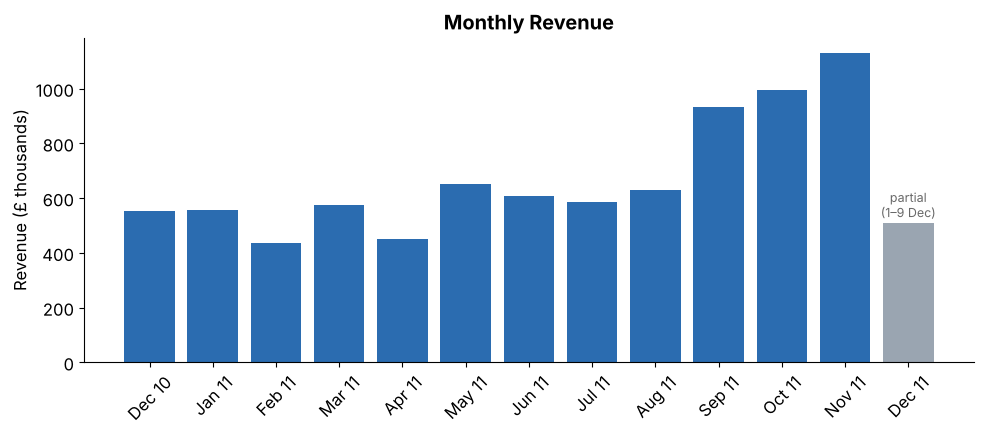

Sep–Nov 2011 vs Jan–Aug 2011 monthly average:
InvoiceDate
2011-09-01     +66%
2011-10-01     +77%
2011-11-01    +101%
Freq: MS, Name: Revenue, dtype: str


In [3]:
monthly = df.set_index('InvoiceDate')['Revenue'].resample('MS').sum()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(monthly.index.strftime('%b %y'), monthly.values / 1e3, color=[GREY if i == len(monthly) - 1 else BLUE for i in range(len(monthly))])
ax.set(title='Monthly Revenue', ylabel='Revenue (£ thousands)')
ax.text(len(monthly) - 1, monthly.iloc[-1] / 1e3 + 20, 'partial\n(1–9 Dec)', ha='center', fontsize=9, color='dimgray')
plt.xticks(rotation=45); fig.tight_layout(); fig.savefig(FIG_DIR / 'monthly_revenue.png', dpi=150); plt.show()

jan_aug = monthly['2011-01':'2011-08'].mean()
print('Sep–Nov 2011 vs Jan–Aug 2011 monthly average:')
print((monthly['2011-09':'2011-11'] / jan_aug - 1).map('{:+.0%}'.format))

United Kingdom: 82.8% of revenue


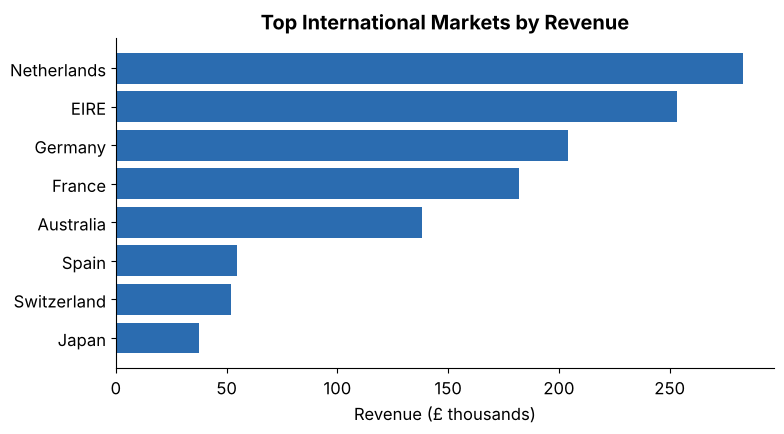

In [4]:
country = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
share = (country / country.sum() * 100).round(1)
print(f"United Kingdom: {share['United Kingdom']}% of revenue")
top_intl = country.drop('United Kingdom').head(8)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_intl.index[::-1], top_intl.values[::-1] / 1e3, color=BLUE)
ax.set(title='Top International Markets by Revenue', xlabel='Revenue (£ thousands)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'international_markets.png', dpi=150); plt.show()

1,130 of 4,327 customers (26.1%) generate 80% of revenue


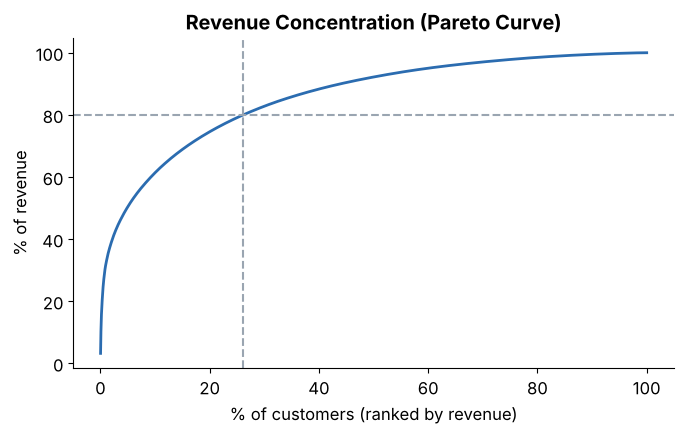

In [5]:
customer_rev = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)
cum_share = customer_rev.cumsum() / customer_rev.sum()
n80 = (cum_share <= 0.80).sum()
print(f'{n80:,} of {len(customer_rev):,} customers ({n80/len(customer_rev):.1%}) generate 80% of revenue')

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(1, len(cum_share) + 1) / len(cum_share) * 100
ax.plot(x, cum_share.values * 100, color=BLUE, lw=2)
ax.axhline(80, color=GREY, ls='--'); ax.axvline(n80 / len(customer_rev) * 100, color=GREY, ls='--')
ax.set(title='Revenue Concentration (Pareto Curve)', xlabel='% of customers (ranked by revenue)', ylabel='% of revenue')
fig.tight_layout(); fig.savefig(FIG_DIR / 'pareto_curve.png', dpi=150); plt.show()

* **Seasonality:** revenue climbs from September and peaks in November, consistent with wholesale holiday stocking. December is partial, because the data ends 9 Dec.
* **Markets:** the UK brings 83% of revenue. The Netherlands, EIRE and Germany lead internationally.
* **Concentration:** 26% of customers generate 80% of revenue, so losing a few top accounts would hurt.

## 4. Order values and hypothesis tests

Order value: mean £469, median £300, skewness 65.1
IQR outlier fence £918: 1,458 orders (7.9%), kept as genuine bulk orders


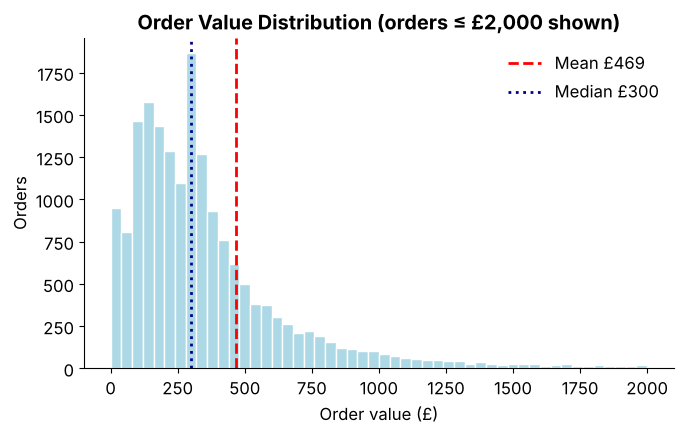

In [6]:
orders = df.groupby('InvoiceNo').agg(Revenue=('Revenue', 'sum'), Country=('Country', 'first'),
                                     Hour=('InvoiceDate', lambda s: s.min().hour))
q1, q3 = orders['Revenue'].quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
print(f"Order value: mean £{orders.Revenue.mean():,.0f}, median £{orders.Revenue.median():,.0f}, "
      f"skewness {orders.Revenue.skew():.1f}")
print(f"IQR outlier fence £{fence:,.0f}: {(orders.Revenue > fence).sum():,} orders "
      f"({(orders.Revenue > fence).mean():.1%}), kept as genuine bulk orders")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(orders.Revenue[orders.Revenue <= 2000], bins=50, color=LIGHT_BLUE, edgecolor='white')
ax.axvline(orders.Revenue.mean(), color='red', ls='--', lw=2, label=f'Mean £{orders.Revenue.mean():,.0f}')
ax.axvline(orders.Revenue.median(), color='darkblue', ls=':', lw=2, label=f'Median £{orders.Revenue.median():,.0f}')
ax.set(title='Order Value Distribution (orders ≤ £2,000 shown)', xlabel='Order value (£)', ylabel='Orders')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / 'order_values.png', dpi=150); plt.show()

Order values are extremely right-skewed, so each comparison below uses two tests. **Welch's t-test** compares means without assuming equal variances. The **Mann-Whitney U test** compares typical orders and isn't driven by a few huge invoices.

In [7]:
def compare(a, b, label_a, label_b):
    t = stats.ttest_ind(a, b, equal_var=False)
    u = stats.mannwhitneyu(a, b)
    return pd.DataFrame({'n': [len(a), len(b)], 'mean £': [a.mean(), b.mean()], 'median £': [a.median(), b.median()]},
                        index=[label_a, label_b]), t.pvalue, u.pvalue

for name, (a, b, la, lb) in {
    'UK vs international': (orders.Revenue[orders.Country == 'United Kingdom'], orders.Revenue[orders.Country != 'United Kingdom'], 'UK', 'International'),
    'Morning vs afternoon': (orders.Revenue[orders.Hour < 12], orders.Revenue[orders.Hour >= 12], 'Morning (<12h)', 'Afternoon (≥12h)'),
}.items():
    table, p_t, p_u = compare(a, b, la, lb)
    print(f'\n{name}: Welch p = {p_t:.2g}, Mann-Whitney p = {p_u:.2g}'); display(table)


UK vs international: Welch p = 3.3e-18, Mann-Whitney p = 6.6e-59


,n,mean £,median £
UK,16548,430.93,293.26
International,1821,812.86,381.60



Morning vs afternoon: Welch p = 0.0018, Mann-Whitney p = 6e-14


,n,mean £,median £
Morning (<12h),6423,534.68,308.48
Afternoon (≥12h),11946,433.37,287.10


* **International orders are larger** (median £382 vs £293). Both tests are significant, which fits wholesale buyers consolidating cross-border shipments.
* **Morning orders are larger** (median £308 vs £287). The effect is statistically significant but small in practical terms.

## 5. SQL analysis
The cleaned table is loaded into SQLite to answer the same questions with window functions and CTEs. The same queries are saved in the repo's `sql/` folder.

In [8]:
con = sqlite3.connect(':memory:')
df.assign(InvoiceDate=df['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')).to_sql('transactions', con, index=False)
q = lambda sql: pd.read_sql(sql, con)

SQL_MOM = """-- Month-over-month revenue growth (window function LAG)
WITH monthly AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           SUM(Revenue)                   AS revenue
    FROM transactions
    GROUP BY month
)
SELECT month,
       ROUND(revenue, 0)                                        AS revenue,
       ROUND(LAG(revenue) OVER (ORDER BY month), 0)             AS prev_month_revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1)           AS growth_pct
FROM monthly
ORDER BY month;"""
q(SQL_MOM)

,month,revenue,prev_month_revenue,growth_pct
0,2010-12,"553,031.00",NaN,NaN
1,2011-01,"555,867.00","553,031.00",0.50
2,2011-02,"437,432.00","555,867.00",-21.30
3,2011-03,"574,947.00","437,432.00",31.40
4,2011-04,"449,531.00","574,947.00",-21.80
5,2011-05,"650,751.00","449,531.00",44.80
6,2011-06,"606,017.00","650,751.00",-6.90
7,2011-07,"585,434.00","606,017.00",-3.40
8,2011-08,"631,170.00","585,434.00",7.80
9,2011-09,"933,428.00","631,170.00",47.90


In [9]:
SQL_TOP = """-- Top 3 customers by revenue in each of the 5 largest non-UK markets (CTE + RANK)
WITH customer_revenue AS (
    SELECT Country, CustomerID, SUM(Revenue) AS revenue
    FROM transactions
    GROUP BY Country, CustomerID
),
top_markets AS (
    SELECT Country
    FROM transactions
    WHERE Country <> 'United Kingdom'
    GROUP BY Country
    ORDER BY SUM(Revenue) DESC
    LIMIT 5
),
ranked AS (
    SELECT cr.*,
           RANK() OVER (PARTITION BY cr.Country ORDER BY cr.revenue DESC) AS country_rank,
           ROUND(100.0 * cr.revenue / SUM(cr.revenue) OVER (PARTITION BY cr.Country), 1) AS pct_of_country
    FROM customer_revenue cr
    JOIN top_markets tm ON tm.Country = cr.Country
)
SELECT Country, CustomerID, ROUND(revenue, 0) AS revenue, pct_of_country, country_rank
FROM ranked
WHERE country_rank <= 3
ORDER BY Country, country_rank;"""
q(SQL_TOP)

,Country,CustomerID,revenue,pct_of_country,country_rank
0,Australia,12415,"124,565.00",90.20,1
1,Australia,12431,"5,515.00",4.00,2
2,Australia,12388,"2,781.00",2.00,3
3,EIRE,14911,"134,166.00",53.00,1
4,EIRE,14156,"114,988.00",45.40,2
5,EIRE,14016,"4,226.00",1.70,3
6,France,12731,"18,752.00",10.30,1
7,France,12678,"16,331.00",9.00,2
8,France,12681,"12,366.00",6.80,3
9,Germany,12471,"17,407.00",8.50,1


In [10]:
SQL_RFM = """-- RFM features per customer in SQL (reference date = day after last invoice)
SELECT CustomerID,
       CAST(julianday((SELECT DATE(MAX(InvoiceDate), '+1 day') FROM transactions))
            - julianday(MAX(InvoiceDate)) AS INTEGER) AS recency_days,
       COUNT(DISTINCT InvoiceNo)                     AS frequency,
       ROUND(SUM(Revenue), 2)                        AS monetary
FROM transactions
GROUP BY CustomerID
ORDER BY monetary DESC
LIMIT 10;"""
q(SQL_RFM)

,CustomerID,recency_days,frequency,monetary
0,14646,1,72,"278,349.22"
1,18102,0,59,"250,414.48"
2,17450,8,46,"194,550.79"
3,16446,0,2,"168,472.50"
4,14911,1,198,"134,166.27"
5,12415,24,20,"124,564.53"
6,14156,9,53,"114,987.83"
7,17511,2,31,"91,011.53"
8,12346,325,1,"77,183.60"
9,16029,38,62,"72,882.09"


Several international markets depend on one or two accounts: one customer generates 98% of Netherlands revenue and 90% of Australia revenue, and two customers make up 98% of EIRE. Losing a single account would effectively lose the market.

## 6. Customer segmentation (RFM + K-Means)

In [11]:
ref_date = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda s: (ref_date - s.max()).days),
                                   Frequency=('InvoiceNo', 'nunique'),
                                   Monetary=('Revenue', 'sum'))
# RFM values are heavily skewed, so log-transform before scaling (otherwise a few huge accounts form their own clusters)
X_rfm = StandardScaler().fit_transform(np.log1p(rfm))
scores = pd.DataFrame([(k, silhouette_score(X_rfm, KMeans(k, n_init=10, random_state=42).fit_predict(X_rfm)))
                       for k in range(2, 8)], columns=['k', 'silhouette'])
scores

,k,silhouette
0,2,0.43
1,3,0.34
2,4,0.34
3,5,0.32
4,6,0.31
5,7,0.31


Silhouette scores are close for k = 3 to 6. **k = 4** gives the most actionable split for marketing, with similar cluster quality to k = 3.

In [12]:
rfm['Cluster'] = KMeans(4, n_init=10, random_state=42).fit_predict(X_rfm)
prof = rfm.groupby('Cluster').agg(Customers=('Recency', 'size'), Recency=('Recency', 'median'),
                                  Frequency=('Frequency', 'median'), Monetary=('Monetary', 'median'),
                                  Revenue=('Monetary', 'sum'))

# Name clusters from their profiles (not hard-coded IDs, so names stay right if cluster numbers change)
names = {}
names[prof['Monetary'].idxmax()] = 'Champions'
names[prof['Recency'].idxmax()] = 'Lost'
rest = prof.drop(list(names)).sort_values('Frequency')
names[rest.index[0]] = 'New / One-time'
names[rest.index[1]] = 'Loyal'
rfm['Segment'] = rfm['Cluster'].map(names)

seg = (rfm.groupby('Segment').agg(Customers=('Recency', 'size'), Median_recency_days=('Recency', 'median'),
                                  Median_orders=('Frequency', 'median'), Median_spend=('Monetary', 'median'),
                                  Revenue=('Monetary', 'sum'))
          .reindex(['Champions', 'Loyal', 'New / One-time', 'Lost']))
seg['% customers'] = seg['Customers'] / seg['Customers'].sum() * 100
seg['% revenue'] = seg['Revenue'] / seg['Revenue'].sum() * 100
seg

,Customers,Median_recency_days,Median_orders,Median_spend,Revenue,% customers,% revenue
Segment,,,,,,,
Champions,691,8.00,10.00,"3,650.41","5,558,283.95",15.97,64.55
Loyal,1186,52.00,4.00,"1,347.64","2,069,770.17",27.41,24.04
New / One-time,808,17.00,2.00,437.75,"417,077.55",18.67,4.84
Lost,1642,173.00,1.00,292.39,"566,107.04",37.95,6.57


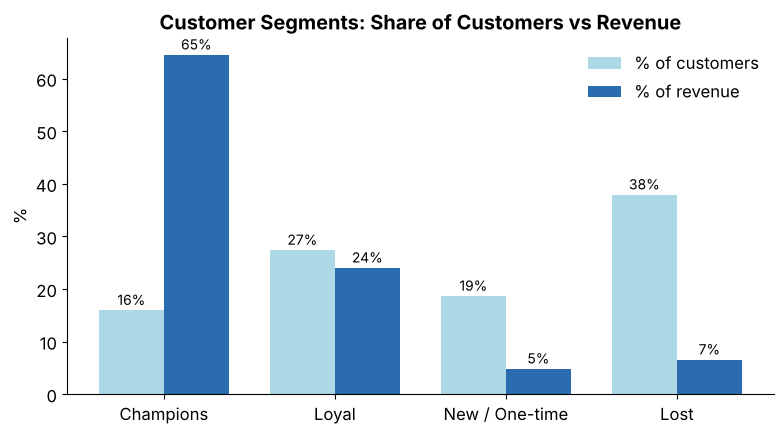

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(seg)); w = 0.38
ax.bar(x - w/2, seg['% customers'], w, color=LIGHT_BLUE, label='% of customers')
ax.bar(x + w/2, seg['% revenue'], w, color=BLUE, label='% of revenue')
for i, (c, r) in enumerate(zip(seg['% customers'], seg['% revenue'])):
    ax.text(i - w/2, c + 1, f'{c:.0f}%', ha='center', fontsize=10); ax.text(i + w/2, r + 1, f'{r:.0f}%', ha='center', fontsize=10)
ax.set_xticks(x, seg.index); ax.set(title='Customer Segments: Share of Customers vs Revenue', ylabel='%')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / 'segments.png', dpi=150); plt.show()

| Segment | Profile | Action |
|---|---|---|
| **Champions** | Ordered within the last ~week, ~10 orders, highest spend; 16% of customers, 65% of revenue | VIP programme, account management, early access |
| **Loyal** | Regular repeat buyers, last order ~7 weeks ago | Loyalty incentives to move them up to Champions |
| **New / One-time** | Recent first or second order | Onboarding sequence to secure a second order within 90 days |
| **Lost** | Single order ~6 months ago | Low-cost win-back campaign; don't overspend |

## 7. Churn prediction without target leakage
A common mistake is to define churn as "Recency > 90 days" and then use Recency as a model input. The model just rediscovers the rule and scores ~100%.

Here the timeline is split instead:
* **Features** come only from purchases **before 11 Sep 2011** (the cutoff).
* **Label:** a customer counts as *churned* if they made **no purchase in the 90 days after the cutoff**.

The model can only use the past to predict the future, the way it would work in production.

In [14]:
end = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
cutoff = end - pd.Timedelta(days=90)
past, future = df[df['InvoiceDate'] < cutoff], df[df['InvoiceDate'] >= cutoff]

cust = past.groupby('CustomerID').agg(
    recency=('InvoiceDate', lambda s: (cutoff - s.max()).days),
    frequency=('InvoiceNo', 'nunique'),
    monetary=('Revenue', 'sum'),
    tenure=('InvoiceDate', lambda s: (cutoff - s.min()).days),
    products=('StockCode', 'nunique'),
    country=('Country', 'first'))
cust['avg_order'] = cust['monetary'] / cust['frequency']
cust['uk'] = (cust['country'] == 'United Kingdom').astype(int)
cust['churned'] = (~cust.index.isin(future['CustomerID'].unique())).astype(int)

print(f'Cutoff: {cutoff:%d %b %Y} | customers active before cutoff: {len(cust):,} | churn rate: {cust.churned.mean():.1%}')

FEATURES = ['recency', 'frequency', 'monetary', 'tenure', 'products', 'avg_order', 'uk']
X = cust[FEATURES].copy()
for c in ['frequency', 'monetary', 'products', 'avg_order']:
    X[c] = np.log1p(X[c])                      # reduce skew
y = cust['churned']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

Cutoff: 11 Sep 2011 | customers active before cutoff: 3,361 | churn rate: 43.0%


In [15]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, probs = [], {}
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    probs[name] = model.predict_proba(X_test)[:, 1]
    rows.append([name, cv_auc.mean(), cv_auc.std(), roc_auc_score(y_test, probs[name])])
probs['Recency only (baseline)'] = X_test['recency']
rows.append(['Recency only (baseline)', np.nan, np.nan, roc_auc_score(y_test, X_test['recency'])])
results = pd.DataFrame(rows, columns=['Model', 'CV AUC (mean)', 'CV AUC (sd)', 'Test AUC'])
results

,Model,CV AUC (mean),CV AUC (sd),Test AUC
0,Logistic regression,0.75,0.01,0.73
1,Random forest,0.75,0.02,0.73
2,Recency only (baseline),NaN,NaN,0.65


Logistic regression on held-out customers (threshold 0.5):
              precision    recall  f1-score   support

      Active       0.75      0.63      0.69       480
     Churned       0.60      0.73      0.66       361

    accuracy                           0.67       841
   macro avg       0.68      0.68      0.67       841
weighted avg       0.69      0.67      0.67       841



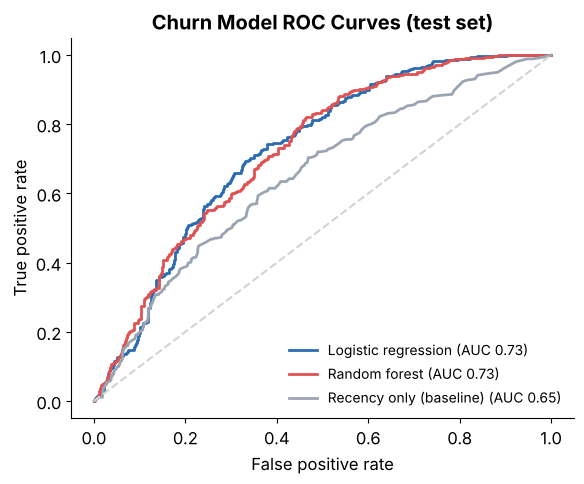

In [16]:
print('Logistic regression on held-out customers (threshold 0.5):')
print(classification_report(y_test, models['Logistic regression'].predict(X_test), target_names=['Active', 'Churned'], digits=2))

fig, ax = plt.subplots(figsize=(6, 5))
for (name, p), color in zip(probs.items(), [BLUE, RED, GREY]):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC {roc_auc_score(y_test, p):.2f})')
ax.plot([0, 1], [0, 1], color='lightgray', ls='--')
ax.set(title='Churn Model ROC Curves (test set)', xlabel='False positive rate', ylabel='True positive rate')
ax.legend(frameon=False, loc='lower right', fontsize=10); fig.tight_layout(); fig.savefig(FIG_DIR / 'churn_roc.png', dpi=150); plt.show()

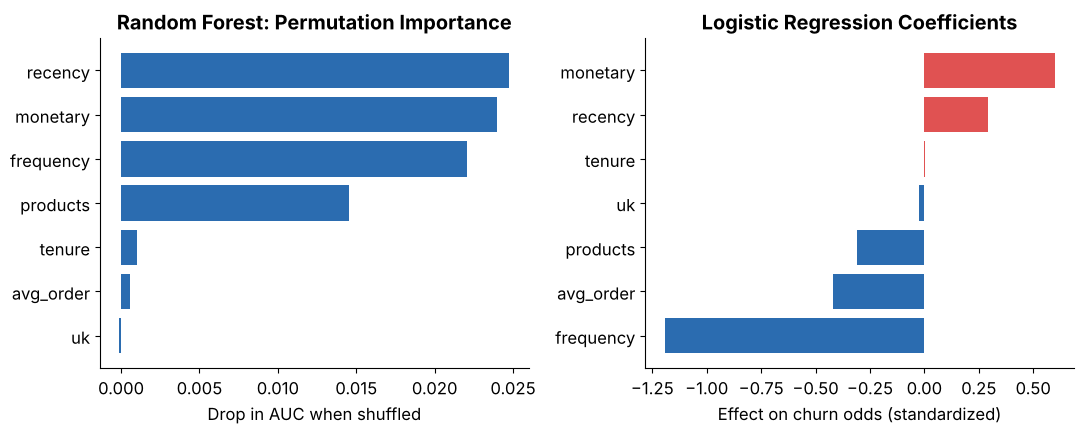

In [17]:
imp = permutation_importance(models['Random forest'], X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=42)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
coef = pd.Series(models['Logistic regression'][-1].coef_[0], index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(importance.index, importance.values, color=BLUE)
axes[0].set(title='Random Forest: Permutation Importance', xlabel='Drop in AUC when shuffled')
axes[1].barh(coef.index, coef.values, color=[RED if v > 0 else BLUE for v in coef.values])
axes[1].set(title='Logistic Regression Coefficients', xlabel='Effect on churn odds (standardized)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'churn_drivers.png', dpi=150); plt.show()

**Interpretation**
* Both models reach a **test AUC of about 0.73** (cross-validated about 0.75), clearly better than ranking customers by recency alone (0.65). That is a realistic level for behavioural churn prediction.
* **Order frequency, spend and recency drive the predictions.** In the random forest, the three matter about equally. In the logistic model, frequency has the largest effect: customers with more past orders are much less likely to churn. Tenure and country add little.
* At the default threshold, the model catches about **73% of churners** with about 60% precision. A retention team can move the threshold depending on what a missed churner costs compared with an unnecessary offer.
* **Limitation:** one year of data allows only one cutoff. With more history, the model should be validated on several time windows.

## 8. Export results for the Power BI dashboard

In [18]:
cust['churn_probability'] = models['Logistic regression'].predict_proba(X)[:, 1]
rfm.join(cust[['churn_probability']]).reset_index().round(3).to_csv(OUT_DIR / 'customer_segments.csv', index=False)
monthly.rename('Revenue').to_frame().to_csv(OUT_DIR / 'monthly_revenue.csv')
country.rename('Revenue').to_frame().to_csv(OUT_DIR / 'revenue_by_country.csv')
print(sorted(p.name for p in OUT_DIR.iterdir()))

['customer_segments.csv', 'monthly_revenue.csv', 'revenue_by_country.csv']


## 9. Conclusions and recommendations
1. **Protect the Champions.** 16% of customers drive 65% of revenue. Assign account management, VIP pricing and early access to the Q4 range.
2. **Win the second order.** Repeat purchasing is one of the strongest predictors of retention, so the most valuable lever is turning one-time buyers into repeat buyers. Use an onboarding sequence and a time-limited reorder incentive within 90 days.
3. **Use the churn score to time win-back offers.** Target Loyal customers whose churn probability rises, before they go dormant. Keep spend on the Lost segment low.
4. **Plan for Q4.** Stock and staffing should anticipate the September to November surge.
5. **Grow international accounts.** International orders are larger, but several markets depend on one or two customers, so diversifying those accounts lowers risk.